In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Chi-Square-Distributions

<Axes: ylabel='Density'>

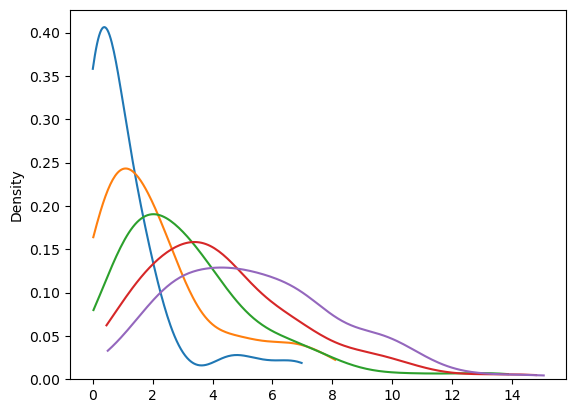

In [2]:
# Generate a sample of 100 number from a standard normal distribution

sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=0, scale=1, size=100)
sample3 = np.random.normal(loc=0, scale=1, size=100)
sample4 = np.random.normal(loc=0, scale=1, size=100)
sample5 = np.random.normal(loc=0, scale=1, size=100)

x = sample1**2
y = sample1**2 + sample2**2
z = sample1**2 + sample2**2 + sample3**2
u = sample1**2 + sample2**2 + sample3**2 + sample4**2
v = sample1**2 + sample2**2 + sample3**2 + sample4**2 + sample5**2

# Plot 

sns.kdeplot(x, clip=(x.min(), x.max()))
sns.kdeplot(y, clip=(y.min(), y.max()))
sns.kdeplot(z, clip=(z.min(), z.max()))
sns.kdeplot(u, clip=(u.min(), u.max()))
sns.kdeplot(v, clip=(v.min(), v.max()))

## Chi-Square Test : 

### 1>. Godness of Fit Test:

In [3]:
import scipy.stats as stats

test_statistic = 1  # Chi-square test_statistic 

degrees_of_freedom = 5  # degrees of freedom

# Calculate the p_value using the chi2 survial function(sf)
p_value = stats.chi2.sf(test_statistic, degrees_of_freedom)
print("P_value : ", p_value)

P_value :  0.9625657732472964


## Case Study

In [4]:
data = pd.read_csv('train.csv')
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Count passanger in each calss

calss_count = data['Pclass'].value_counts().sort_index()
calss_count

Pclass
1    216
2    184
3    491
Name: count, dtype: int64

In [6]:
# Calculate the expected count assuming a uniform distributions

total_passengers = len(data)
expected_count = total_passengers / 3
expected = [expected_count] * 3

print("Expected Passenger count (assuming uniform distributions):", expected)

Expected Passenger count (assuming uniform distributions): [297.0, 297.0, 297.0]


In [7]:
from scipy.stats import chisquare

In [8]:
# Perform the chi-square Goodness of fit test

chi2, p_value = chisquare(calss_count, expected)

# Print the result
print("\n chi-square statistic: {: .2f}".format(chi2))
print("P_value: {: .4f}".format(p_value))


 chi-square statistic:  191.80
P_value:  0.0000


In [9]:
data.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


## 2>. Test of Independance

### Case Study

In [11]:
# We will use the chi-square test for independence to see if the survial rate of passenger is independent of the passenger class

contingency_table = pd.crosstab(data['Survived'], data['Pclass'])
contingency_table

Pclass,1,2,3
Survived,,,
0,80,97,372
1,136,87,119


In [14]:
from scipy.stats import chi2_contingency

In [16]:
# Perform the chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# print the result
print("\n Chi-Square Statistic: {:.2f}".format(chi2))
print("P_value: {:.4f}".format(p_value))
print("Degrees of Freedom: {}".format(dof))
print("Expected Frequencies: \n {}".format(expected))


 Chi-Square Statistic: 102.89
P_value: 0.0000
Degrees of Freedom: 2
Expected Frequencies: 
 [[133.09090909 113.37373737 302.53535354]
 [ 82.90909091  70.62626263 188.46464646]]


In [17]:
# Interpret the result

alpha = 0.05
if p_value < alpha:
    print("\nWe reject the null hypothesis. There is a significant association between class and survival rate.")
else:
    print("\nWe fail to reject the null hypothesis. There is no significant association between passenger class and survival rate.")


We reject the null hypothesis. There is a significant association between class and survival rate.
